<h1 style="
    font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif;
    font-size: 36px;
    color: #ffffff;
    background-color: #9E1B32;
    padding: 20px;
    border-radius: 12px;
    text-align: center;
    box-shadow: 0px 4px 10px rgba(0, 0, 0, 0.1);">
    Model Evaluation During Extreme Events
</h1>

**Authors:** 

<ul style="line-height:1.5;">
<li>Savalan Naser Neisary <a href="mailto:snaserneisary@crimson.ua.edu">(snaserneisary@crimson.ua.edu)</a></li>
</ul>


**Last Updated:** 10/10/2026

**Purpose:**

The goal in this notebook is to evaluate the model for different inputs from 2002 to 2022 across the entire time frame, during extreme events using the Streamflow Extreme Event Dataset (SEED) and it performance in capturing streamflow drought events. For more information about SEED please read 
<span style="background-color:rgba(184,34,61,0.12); padding:4px 6px; border-radius:6px;">
  <a href="https://doi.org/10.1111/1752-1688.70093" target="_blank" style="font-weight:bold; color:#E04A63;">
    Model-Agnostic Framework for Evaluating Hydrological Models Under Extreme Events Across the Contiguous United States paper
  </a>
</span>.

**Audience:**

Researchers and practitioners working with NextGen hydrologic simulations. Users should be familiar with Python, Jupyter Notebooks, and basic hydrologic modeling concepts.

**Description:**

<div style="font-size:14px; margin-bottom:0; padding-bottom:0;">

- We first evaluate the NextGen LSTM module with NWM compared to observations using two different forcings from 2002 to 2022.
- Then we evaluate its capability in capturing streamflow drought events.
- Finally we evalute the models during extreme drought and flood events. 
</div>
<div style="margin-top:-16px;"></div>

**Data Description:**

We have four streamflow datasets, including NWM retrospective, USGS observations, and two NextGen simulations with two different forcings, and the SEED data for one station in Alabama.


<div style="
    padding: 15px 20px; 
    background-color: rgba(184,34,61,0.12); 
    border-left: 6px solid #9E1B32; 
    border-radius: 4px; 
    margin-bottom: 20px;
    font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;
">
    <h3 style="margin-top: 0; font-weight: 700; display: flex; align-items: center; gap: 8px;">
        💡 Quick Note Before You Begin
    </h3>
    <p style="margin-bottom: 10px; font-size: 1.05em;">
        So that everything runs smoothly and all settings start correctly, <strong>please restart the kernel before running the cells below</strong> by opening the <strong>Kernel</strong> menu at the top and choosing <span style="background-color: rgba(0,0,0,0.05); padding: 2px 6px; border-radius: 3px; border: 1px solid rgba(0,0,0,0.1);"><strong>“Restart Kernel and Clear Outputs of All Cells”</strong></span>.
    </p>

</div>

<div style="background:#9E1B32; border-left:6px solid #F0627A; padding:12px 16px; border-radius:8px; margin-top:0; margin-bottom:0;">
  <h3 style="margin:0; font-size:20px; font-weight:700; color:#fff5f7;">
    1. Prepare the Python Environment
  </h3>
</div>

We prepare the **Python environment** by importing all required libraries and utilities used throughout this TEEHR evaluation workflow, which supports **data processing**, **time-series visualization**, and **NextGen/TEEHR evaluation**.

In [1]:
from utils.drought_events import (
    load_daily_flows,
    metrics_table,
    run_drought_comparison,
    key_observed_events,
    event_metrics,
    period_metrics,
    plot_metrics_bars,
    plot_period_series,
)

<jemalloc>: MADV_DONTNEED does not work (memset will be used instead)
<jemalloc>: (This is the expected behaviour if you are running under QEMU)


<div style="background:#9E1B32; border-left:6px solid #F0627A; padding:12px 16px; border-radius:8px; margin-top:0; margin-bottom:0;">
  <h3 style="margin:0; font-size:20px; font-weight:700; color:#fff5f7;">
    2. Model Performance over the Entire Period (2002–2022)
  </h3>
</div>

<p style="margin-top:0; padding-top:4px;">
Here we compare every model with the USGS observations over the whole record, using daily flow (m³/s) on the days that all datasets have (2002-01-01 to 2022-12-30). The models are the <strong>NWM retrospective</strong> and the <strong>NextGen LSTM runs</strong> (one column per forcing). The daily flows are stored in <code>data/daily_flows.parquet</code>.
</p>

<div style="background-color:rgba(184,34,61,0.12); border-left: 5px solid #E04A63; padding: 14px; border-radius: 8px; font-family: 'Segoe UI', sans-serif; font-size: 15px; margin-top: 10px;">
  <strong>Metrics (each model vs. USGS observations):</strong>
  <ul style="margin-top: 8px; margin-bottom: 0;">
    <li><strong>KGE</strong> (Kling-Gupta Efficiency): combines correlation, variability and bias. Best = 1.</li>
    <li><strong>NSE</strong> (Nash-Sutcliffe Efficiency): how well the model matches the observations, mostly driven by high flows. Best = 1; below 0 is worse than using the observed mean.</li>
    <li><strong>NNSE</strong> (Normalized NSE): NSE rescaled to 0–1. Best = 1.</li>
    <li><strong>logNSE</strong>: NSE of the log of flow, which gives more weight to low flows. Best = 1.</li>
    <li><strong>RMSE</strong> (Root Mean Square Error, m³/s): typical size of the error. Best = 0.</li>
    <li><strong>PBIAS</strong> (Percent Bias, %): total volume error. Best = 0; positive means the model is too high.</li>
  </ul>
</div>


In [3]:
SITE_NO = "02450250"

# Daily flows (m³/s): Observed (USGS), NWM and each NextGen run
flows = load_daily_flows(models=["NWM", "NextGen (AORC)", "NextGen (IMERG)"])
flows.head()

,Observed,NWM,NextGen (AORC),NextGen (IMERG)
date,,,,
2002-01-01,2.944952,3.334583,2.826128,2.826128
2002-01-02,2.712754,3.325000,4.067172,4.078494
2002-01-03,2.571170,3.300833,3.914525,3.955611
2002-01-04,2.304991,3.043333,3.671709,3.721935
2002-01-05,2.191724,2.815833,3.689029,3.750104


<h4 style="background-color:rgba(184,34,61,0.18); padding:8px 12px; border-left: 5px solid #E04A63; border-radius:6px; font-family:'Segoe UI',sans-serif; font-size:16px; margin-top:16px;">
🔹 Metrics for the Entire Period
</h4>
<p style="font-family:'Segoe UI',sans-serif; font-size:15px; margin-top:6px;">
One panel per metric and one bar per model. The dashed line shows the best possible value of each metric (a perfect match with the observations).
</p>


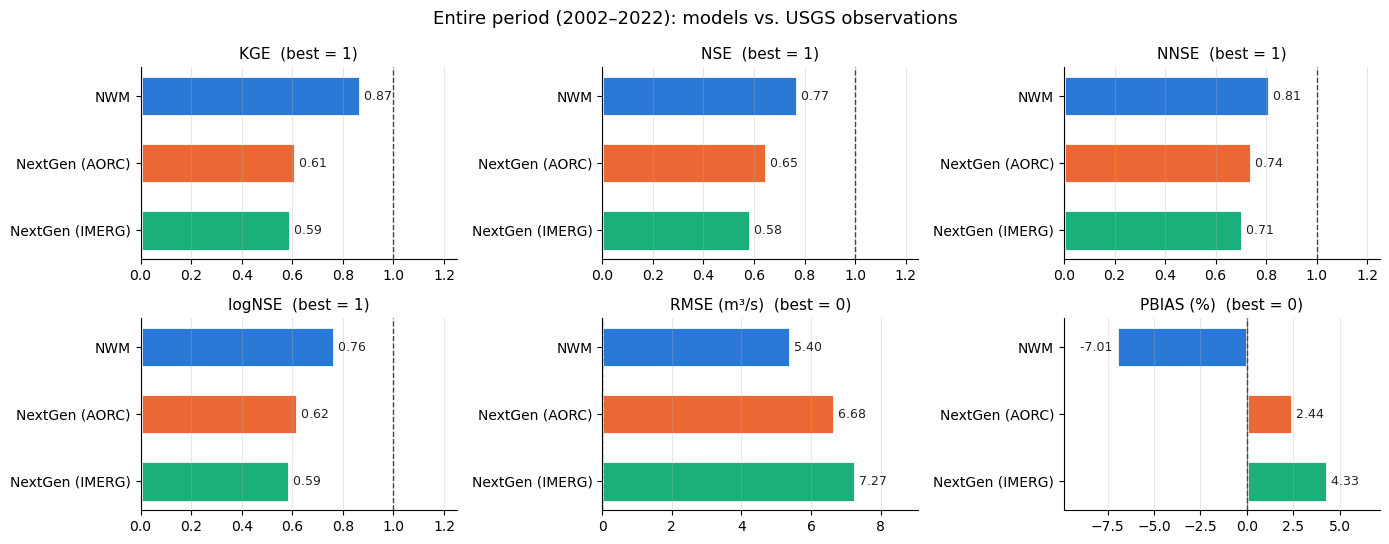

In [4]:
# Metrics of every model against USGS observations, on the days all models have
all_period_metrics = metrics_table(flows.dropna())
plot_metrics_bars(all_period_metrics, title="Entire period (2002–2022): models vs. USGS observations")

<div style="background:#9E1B32; border-left:6px solid #F0627A; padding:12px 16px; border-radius:8px; margin-top:0; margin-bottom:0;">
  <h3 style="margin:0; font-size:20px; font-weight:700; color:#fff5f7;">
    3. Daily Flow Comparison and Drought Events (Observed vs. NWM vs. NextGen)
  </h3>
</div>

<p style="margin-top:0; padding-top:4px;">

Observed (USGS), NWM and NextGen daily flows (m³/s) are stored in `data/daily_flows.parquet`.
Daily drought thresholds (1980–2025) are read from `data/drought_thresholds.parquet`.
</p>



### Drought events

Choose the drought threshold (Q95, Q90, Q80 or Q70), the minimum event length (persistence) and the largest gap that still joins two events.
Severity = mean % below the threshold over the drought days of an event.

In [5]:
# ------------------ Your choices ------------------
Q_LEVEL = 80            # 95, 90, 80 or 70
PERSISTENCE_DAYS = 7    # minimum event length (days)
GAP_DAYS = 3            # events separated by this many days or fewer are joined
# --------------------------------------------------

drought_summary, drought_events, drought_threshold = run_drought_comparison(
    flows,
    site_no=SITE_NO,
    q=Q_LEVEL,
    persistence_days=PERSISTENCE_DAYS,
    gap_days=GAP_DAYS,
)
drought_summary

Station 02450250 | threshold Q80 | persistence 7 d | gap 3 d | 2002-01-01 to 2023-01-30 (7700 days)


,Observed,NWM,NextGen (AORC),NextGen (IMERG),NWM - Observed,NextGen (AORC) - Observed,NextGen (IMERG) - Observed
n_events,57.000000,31.000000,8.000000,8.000000,-26.000000,-49.000000,-49.000000
duration_min_days,7.000000,7.000000,7.000000,7.000000,0.000000,0.000000,0.000000
duration_median_days,13.000000,20.000000,14.000000,11.500000,7.000000,1.000000,-1.500000
duration_max_days,93.000000,197.000000,53.000000,22.000000,104.000000,-40.000000,-71.000000
severity_min_pct,0.507307,3.684859,7.769178,7.492655,3.177552,7.261870,6.985348
severity_median_pct,22.962792,21.467264,20.132635,17.373252,-1.495529,-2.830158,-5.589540
severity_max_pct,62.862493,73.585680,26.762821,32.746204,10.723187,-36.099672,-30.116289


In [6]:
# Events found in each series
for name, events in drought_events.items():
    print(f"--- {name}: {len(events)} events")
    display(events)

--- Observed: 57 events


,start,end,duration_days,severity_pct,min_flow_cms
0,2002-01-12,2002-01-18,7,13.869679,1.597070
1,2002-02-19,2002-03-11,21,25.052068,1.755644
2,2003-01-15,2003-01-28,14,23.501421,1.322397
3,2004-03-25,2004-04-11,18,25.978597,1.415842
4,2005-05-17,2005-05-31,15,16.539041,0.362456
5,2006-03-03,2006-03-09,7,16.830224,2.143585
6,2006-06-12,2006-06-22,11,12.918733,0.261931
7,2006-07-01,2006-07-28,28,32.859268,0.095428
8,2006-08-15,2006-09-11,28,38.993724,0.048139
9,2006-12-08,2006-12-24,17,23.826231,0.552179


--- NWM: 31 events


,start,end,duration_days,severity_pct,min_flow_cms
0,2002-02-23,2002-03-11,17,21.467264,2.030417
1,2003-03-29,2003-04-06,9,9.409959,2.165417
2,2004-03-25,2004-04-25,32,9.694270,1.564583
3,2006-03-05,2006-03-19,15,15.583209,2.180833
4,2006-10-24,2006-11-06,14,37.768645,0.090000
5,2006-11-21,2006-12-30,40,36.667731,0.192500
6,2007-03-09,2007-05-04,57,26.087225,1.040833
7,2007-09-20,2008-04-03,197,73.585680,0.020000
8,2008-04-08,2008-05-01,24,12.311605,1.265417
9,2008-10-14,2008-12-09,57,62.146191,0.050000


--- NextGen (AORC): 8 events


,start,end,duration_days,severity_pct,min_flow_cms
0,2007-03-14,2007-04-10,28,23.072509,1.431651
1,2007-12-08,2008-01-29,53,23.682974,0.429546
2,2008-11-28,2008-12-04,7,17.783422,0.328706
3,2009-02-06,2009-02-25,20,7.769178,2.126252
4,2011-02-24,2011-03-04,9,8.341947,2.228764
5,2012-04-04,2012-04-17,14,19.705773,1.364780
6,2016-11-15,2016-11-28,14,20.559496,0.235682
7,2017-02-17,2017-02-27,11,26.762821,1.639840


--- NextGen (IMERG): 8 events


,start,end,duration_days,severity_pct,min_flow_cms
0,2007-03-14,2007-04-04,22,27.625103,1.448661
1,2007-12-08,2007-12-20,13,32.746204,0.378008
2,2007-12-26,2008-01-10,16,16.843164,1.004416
3,2008-01-15,2008-01-22,8,11.894568,1.758098
4,2012-04-10,2012-04-17,8,14.566986,1.598544
5,2016-11-14,2016-11-28,15,18.246730,0.234134
6,2017-02-18,2017-02-27,10,17.903341,2.014262
7,2017-04-16,2017-04-22,7,7.492655,1.409558


<div style="background:#9E1B32; border-left:6px solid #F0627A; padding:12px 16px; border-radius:8px; margin-top:0; margin-bottom:0;">
  <h3 style="margin:0; font-size:20px; font-weight:700; color:#fff5f7;">
    4. Model Performance during SEED Extreme Events
  </h3>
</div>

<p style="margin-top:0; padding-top:4px;">
The <strong>Streamflow Extreme Event Dataset (SEED)</strong> lists the dates of extreme flood and drought events at USGS gages. For our station, <strong>USGS 02450250 (Sipsey Fork near Grayson, AL; NWM COMID 18578829)</strong>, SEED has one flood and one drought event, both with a <strong>100-year return period</strong>:
</p>

<table style="border-collapse: collapse; font-size: 14px;">
  <thead>
    <tr style="background-color: #ffffff; color: #9E1B32;">
      <th style="padding: 8px; text-align: left; color: #9E1B32; border-bottom: 2px solid #9E1B32;">Event</th>
      <th style="padding: 8px; text-align: left; color: #9E1B32; border-bottom: 2px solid #9E1B32;">Start</th>
      <th style="padding: 8px; text-align: left; color: #9E1B32; border-bottom: 2px solid #9E1B32;">End</th>
      <th style="padding: 8px; text-align: left; color: #9E1B32; border-bottom: 2px solid #9E1B32;">Return period</th>
    </tr>
  </thead>
  <tbody>
    <tr><td style="padding: 8px;">Flood</td><td style="padding: 8px;">2023-01-25</td><td style="padding: 8px;">2023-02-08</td><td style="padding: 8px;">100 years</td></tr>
    <tr><td style="padding: 8px;">Drought</td><td style="padding: 8px;">2021-07-26</td><td style="padding: 8px;">2021-08-25</td><td style="padding: 8px;">100 years</td></tr>
  </tbody>
</table>

<p style="margin-top:10px;">
We compute the same metrics as in Section 2, separately for each event window. The model runs end on 2023-01-30, so for the flood we only use its first 6 days (2023-01-25 to 2023-01-30); the peak on 2023-02-03 is not covered. The IMERG run ends on 2022-12-30, so it has no flow in the flood window. The windows are short (6 and 31 days), so the metrics change a lot with small errors and should be compared between models rather than with the full-period values.
</p>


<h4 style="background-color:rgba(184,34,61,0.18); padding:8px 12px; border-left: 5px solid #E04A63; border-radius:6px; font-family:'Segoe UI',sans-serif; font-size:16px; margin-top:16px;">
🔹 SEED Flood Event (2023-01-25 to 2023-01-30, first 6 days)
</h4>


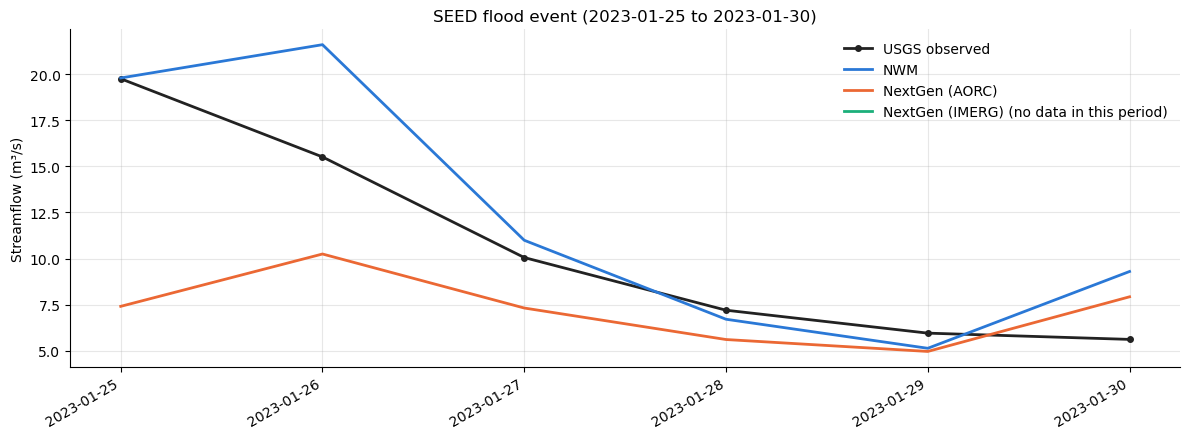

In [7]:
# Daily streamflow during the SEED flood event
plot_period_series(flows, "2023-01-25", "2023-01-30", title="SEED flood event")

2023-01-25 to 2023-01-30: 6 days


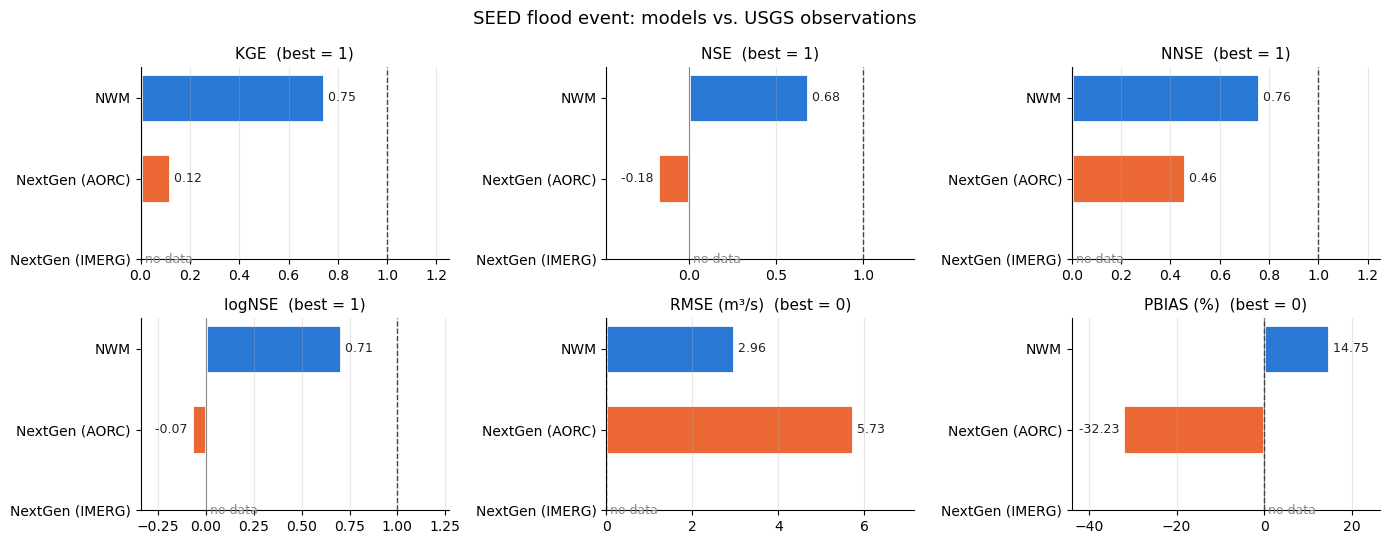

In [8]:
# Metrics of every model against USGS observations during the SEED flood event
flood_metrics = period_metrics(flows, "2023-01-25", "2023-01-30")
plot_metrics_bars(flood_metrics, title="SEED flood event: models vs. USGS observations")

<h4 style="background-color:rgba(184,34,61,0.18); padding:8px 12px; border-left: 5px solid #E04A63; border-radius:6px; font-family:'Segoe UI',sans-serif; font-size:16px; margin-top:16px;">
🔹 SEED Drought Event (2021-07-26 to 2021-08-25)
</h4>


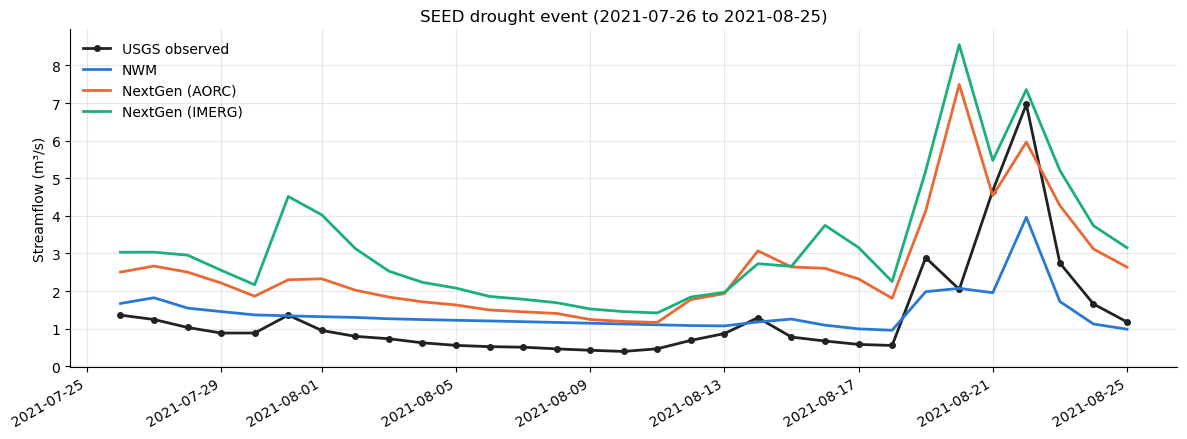

In [9]:
# Daily streamflow during the SEED drought event
plot_period_series(flows, "2021-07-26", "2021-08-25", title="SEED drought event")

2021-07-26 to 2021-08-25: 31 days


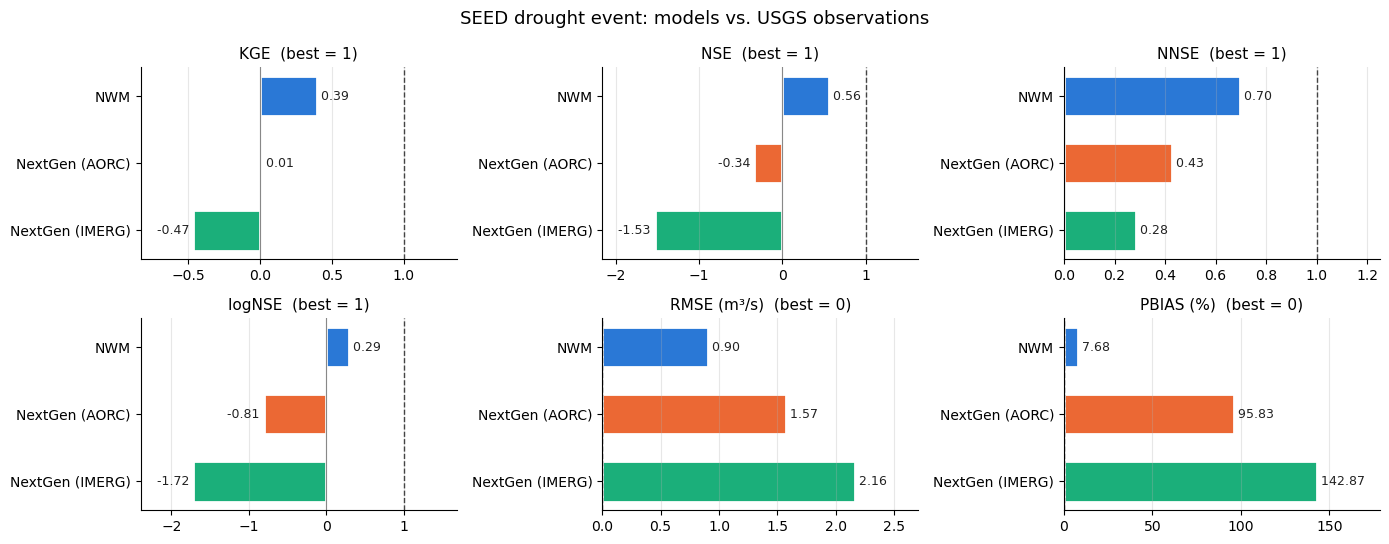

In [10]:
# Metrics of every model against USGS observations during the SEED drought event
drought_metrics = period_metrics(flows, "2021-07-26", "2021-08-25")
plot_metrics_bars(drought_metrics, title="SEED drought event: models vs. USGS observations")